# 01 – Data Exploration: CIFAKE

**Goal:** understand the CIFAKE dataset before training any model.

**Dataset:** [CIFAKE](https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images): 60,000 real images (CIFAR-10) and 60,000 AI-generated images (Stable Diffusion v1.4), 32×32 RGB.

In [1]:
import os
import kagglehub

DATA_ROOT = kagglehub.dataset_download("birdy654/cifake-real-and-ai-generated-synthetic-images")
print("Data is in:", DATA_ROOT)

for folder, subfolders, files in os.walk(DATA_ROOT):
    print(f"{folder} -> {len(files)} files")

Data is in: /kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images
/kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images -> 0 files
/kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/test -> 0 files
/kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/test/FAKE -> 10000 files
/kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/test/REAL -> 10000 files
/kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/train -> 0 files
/kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/train/FAKE -> 50000 files
/kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/train/REAL -> 50000 files


In [2]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(DATA_ROOT)

rows = []
for split in ["train", "test"]:
    for label in ["REAL", "FAKE"]:
        for image_path in (DATA_DIR / split / label).iterdir():
            rows.append({"path": str(image_path), "split": split, "label": label})

df = pd.DataFrame(rows)
print("Table shape:", df.shape)
df.head()

Table shape: (120000, 3)


,path,split,label
0,/kaggle/input/datasets/birdy654/cifake-real-an...,train,REAL
1,/kaggle/input/datasets/birdy654/cifake-real-an...,train,REAL
2,/kaggle/input/datasets/birdy654/cifake-real-an...,train,REAL
3,/kaggle/input/datasets/birdy654/cifake-real-an...,train,REAL
4,/kaggle/input/datasets/birdy654/cifake-real-an...,train,REAL


In [3]:
pd.crosstab(df["split"], df["label"],margins=True)

label,FAKE,REAL,All
split,,,
test,10000,10000,20000
train,50000,50000,100000
All,60000,60000,120000


In [4]:
df["path"].str.split(".").str[-1].value_counts()

path
jpg    120000
Name: count, dtype: int64

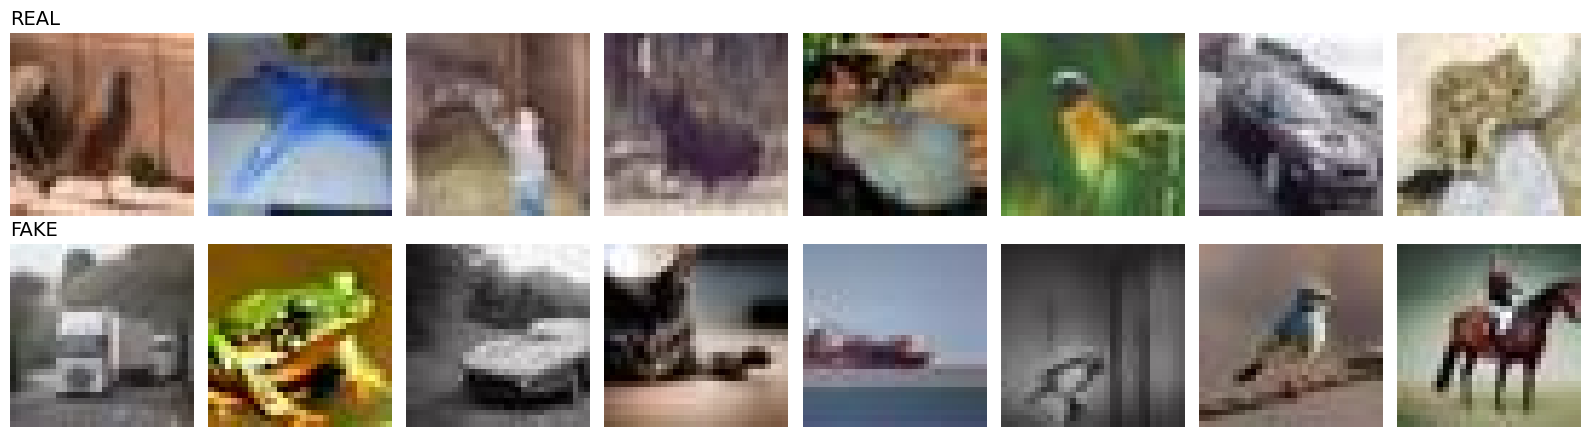

In [5]:
import matplotlib.pyplot as plt 
from PIL import Image

train_df = df[df["split"] == "train"]
real_sample = train_df[train_df["label"] == "REAL"].sample(8, random_state = 42)
fake_sample = train_df[train_df["label"] == "FAKE"].sample(8, random_state = 42)

fig, axes = plt.subplots(2, 8, figsize = (16, 4.5))

for ax, path in zip(axes[0], real_sample["path"]):
    ax.imshow(Image.open(path))
    ax.axis("off")

for ax, path in zip(axes[1], fake_sample["path"]):
    ax.imshow(Image.open(path))
    ax.axis("off")

axes[0, 0].set_title("REAL", loc="left", fontsize=14)
axes[1, 0].set_title("FAKE", loc="left", fontsize=14)

plt.tight_layout()
plt.show()

In [6]:
sample = df.sample(1000, random_state=42)

sizes = []
modes = []

for path in sample["path"]:
    with Image.open(path) as img:
        sizes.append(img.size)
        modes.append(img.mode)

print(pd.Series(sizes).value_counts())
print(pd.Series(modes).value_counts())

(32, 32)    1000
Name: count, dtype: int64
RGB    1000
Name: count, dtype: int64


In [7]:
import numpy as np

def image_stats(path):
    """Return simple numeric features that describe one image."""
    with Image.open(path) as img:
        rgb = np.asarray(img, dtype = np.float32) / 255.0
        hsv = np.asarray(img.convert("HSV"), dtype = np.float32) / 255.0

    gray = rgb.mean(axis=2)

    sharpness = (np.abs(np.diff(gray, axis=0)).mean() + np.abs(np.diff(gray, axis=1)).mean())

    return {
        "brightness": gray.mean(),
        "contrast": gray.std(),
        "saturation": hsv[:, :, 1].mean(),
        "sharpness": sharpness,
    }

stats_sample = train_df.groupby("label").sample(2000, random_state=42)

stats = pd.DataFrame([image_stats(p) for p in stats_sample["path"]])
stats["label"] = stats_sample["label"].values

stats.groupby("label").mean()

,brightness,contrast,saturation,sharpness
label,,,,
FAKE,0.427614,0.197566,0.357525,0.126357
REAL,0.473920,0.196600,0.275854,0.118142


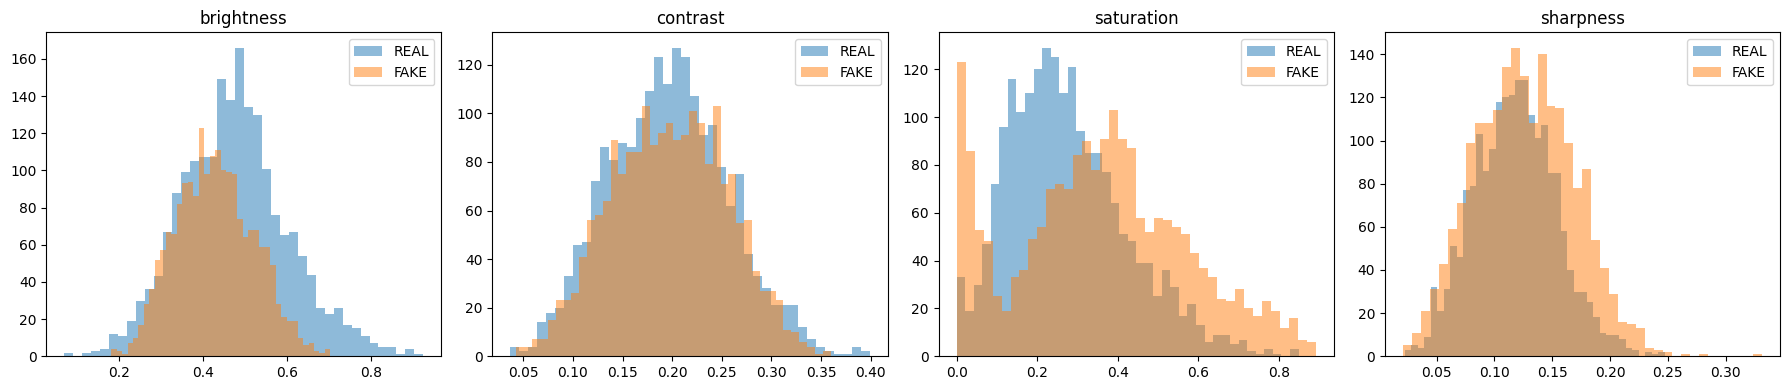

In [8]:
features = ["brightness", "contrast", "saturation", "sharpness"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, feature in zip(axes, features):
    for label in ["REAL", "FAKE"]:
        values = stats.loc[stats["label"] == label, feature]
        ax.hist(values, bins=40, alpha=0.5, label=label)
        ax.set_title(feature)
        ax.legend()

plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

X = stats[features]
y = (stats["label"] == "FAKE").astype(int)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model= make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)

print(f"Validation accuracy: {model.score(X_val, y_val):.1%}")

Validation accuracy: 57.3%


### Findings from pixel statistics
- **Saturation** is the clearest difference: FAKE images are more colorful on average, but also include fully grayscale images (spike at 0).
- **Sharpness** is slightly *higher* for FAKE images, which contradicts the visual impression that they look smoother.
- **Brightness** is slightly lower for FAKE; **contrast** shows no difference.
- The distributions overlap heavily, so no single simple feature separates the classes. This motivates a learned model (CNN).

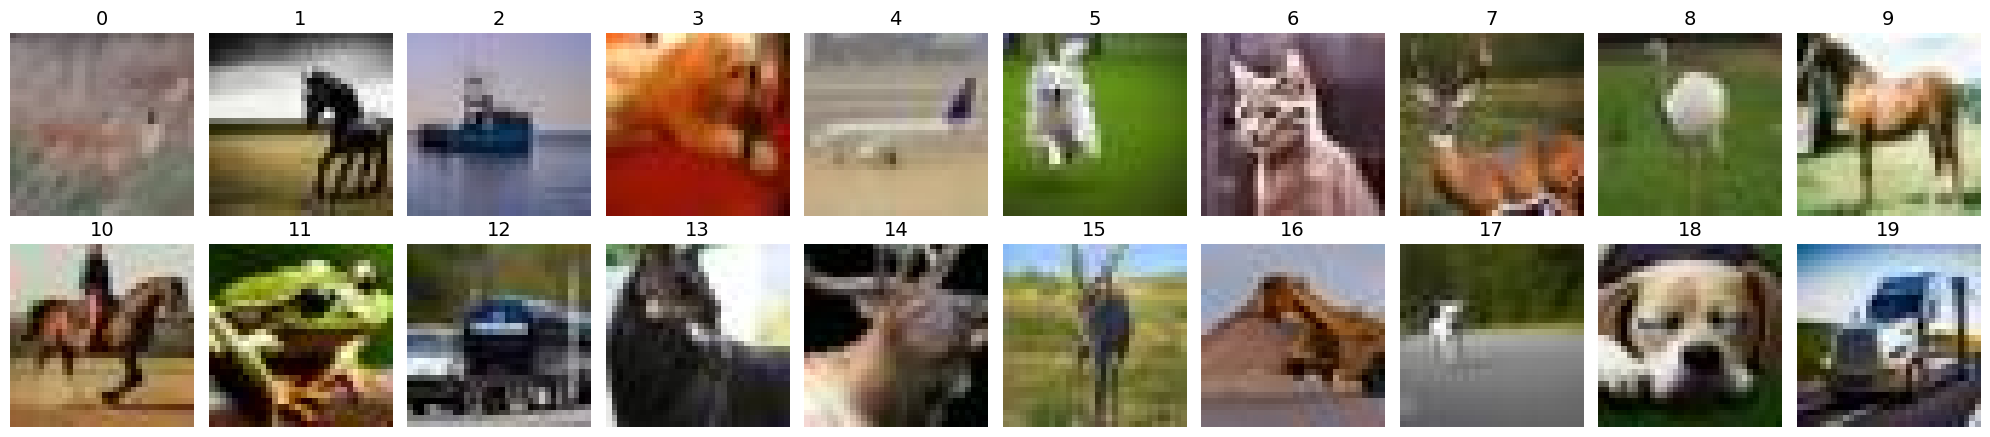

In [10]:
quiz = train_df.sample(20, random_state=7).reset_index(drop=True)

fig, axes = plt.subplots(2, 10, figsize=(20, 4.5))

for i, (ax, path) in enumerate(zip(axes.flat,quiz["path"])):
    ax.imshow(Image.open(path))
    ax.set_title(i, fontsize=14)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
my_guesses = "RFRRFFRFRRFRFFRRFRFR"
assert len(my_guesses) == 20, "You need exactly 20 guesses"

truth = quiz["label"].str[0]
correct = pd.Series(list(my_guesses)) == truth

print(f"My accuracy: {correct.mean():.0%}")
quiz.assign(guess=list(my_guesses),
correct=correct)[["label", "guess", "correct"]]

My accuracy: 65%


,label,guess,correct
0,REAL,R,True
1,FAKE,F,True
2,FAKE,R,False
3,REAL,R,True
4,REAL,F,False
5,FAKE,F,True
6,FAKE,R,False
7,FAKE,F,True
8,REAL,R,True
9,REAL,R,True


- **Human baseline:** I classified 20 random training images by eye and got **65%** correct (13/20). With only 20 images this estimate is very uncertain (roughly 43–82%), but it suggests humans find this task hard too.